# Vector Embeddings, Semantic Similarity, and Vector Databases  
## Interactive Jupyter Notebook

Welcome to the embeddings and vector databases lesson.

In the previous lesson, you learned that text becomes:

```text
Raw text → Tokens → Token IDs
```

But token IDs are only labels.

For example:

```text
cat → 45
kitten → 9002
```

The computer does not automatically know that `cat` and `kitten` are related.

In this lesson, you will learn how embeddings solve that problem.

---

## Learning Objectives

By the end of this notebook, you should be able to:

1. Explain why token IDs do not represent meaning.
2. Define vector embeddings.
3. Represent words/items as coordinates in vector space.
4. Calculate Euclidean distance.
5. Calculate cosine similarity.
6. Compare keyword search and semantic search.
7. Build a simple semantic search system using vectors.
8. Use ChromaDB to store and query documents.
9. Add metadata and URIs to vector database entries.
10. Explain how vector databases support AI memory and retrieval.

# Part 1: From Token IDs to Meaning

Token IDs are lookup labels.

They are useful for identifying tokens, but they do not tell the computer what the token means.

Example:

```text
cat → 45
kitten → 9002
```

The model does not know that these are related just from the IDs.

Embeddings solve this by turning text into vectors:

```text
cat    → [0.21, -0.44, 0.78, ...]
kitten → [0.23, -0.41, 0.75, ...]
```

Similar meanings tend to have similar vectors.

In [55]:
token_ids = {
    "cat": 45,
    "kitten": 9002,
    "banana": 17
}

print(token_ids)

print("\nImportant:")
print("These IDs are labels. They do not contain meaning by themselves.")

{'cat': 45, 'kitten': 9002, 'banana': 17}

Important:
These IDs are labels. They do not contain meaning by themselves.


# Part 2: What Is an Embedding?

An embedding is a list of numbers that represents meaning.

A simple 2D example:

```text
doctor    → [0.91, 0.10]
physician → [0.89, 0.12]
banana    → [0.05, 0.93]
```

Doctor and physician are close together because they have similar meaning.

Banana is far away because it belongs to a different category.

Think of an embedding as:

```text
GPS coordinate for meaning
```

In [56]:
import numpy as np
import matplotlib.pyplot as plt

embeddings_2d = {
    "doctor": np.array([0.91, 0.10]),
    "physician": np.array([0.89, 0.12]),
    "nurse": np.array([0.82, 0.18]),
    "banana": np.array([0.05, 0.93]),
    "apple": np.array([0.08, 0.88]),
    "train": np.array([0.55, 0.45])
}

for word, vector in embeddings_2d.items():
    print(word, "→", vector)

doctor → [0.91 0.1 ]
physician → [0.89 0.12]
nurse → [0.82 0.18]
banana → [0.05 0.93]
apple → [0.08 0.88]
train → [0.55 0.45]


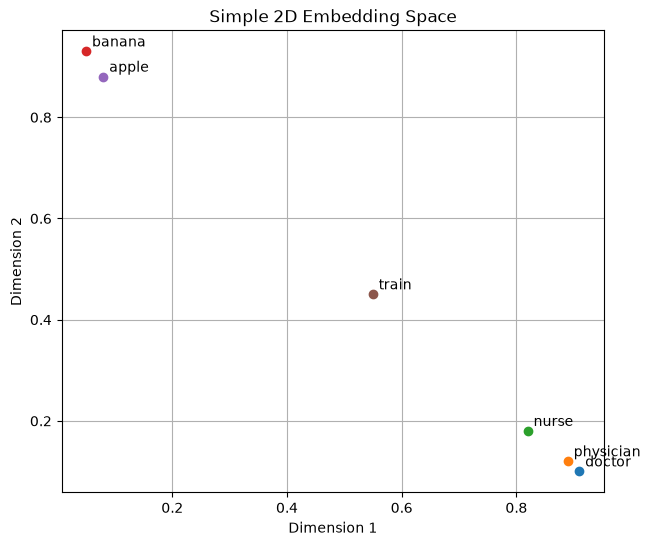

In [57]:
plt.figure(figsize=(7, 6))

for word, vector in embeddings_2d.items():
    plt.scatter(vector[0], vector[1])
    plt.text(vector[0] + 0.01, vector[1] + 0.01, word)

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("Simple 2D Embedding Space")
plt.grid(True)
plt.show()

## Practice 1: Add Your Own Words

Add three new words to the `embeddings_2d` dictionary.

Try adding words that should be close to existing ones.

Examples:

- surgeon
- orange
- airplane

Then rerun the plot.

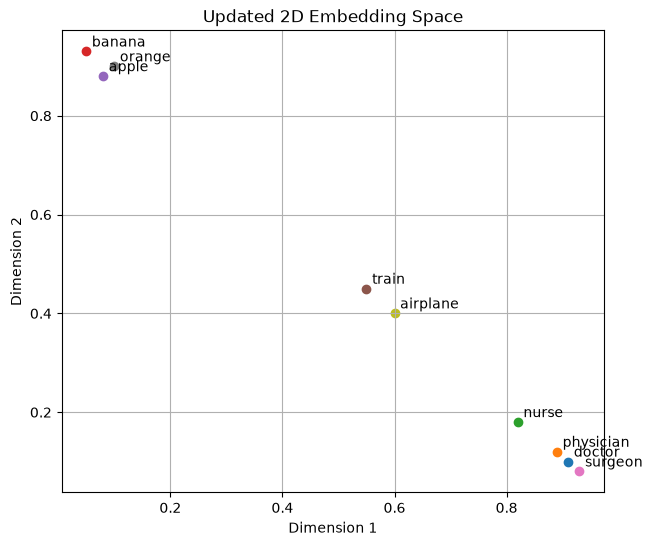

In [58]:
# Practice 1

embeddings_2d["surgeon"] = np.array([0.93, 0.08])
embeddings_2d["orange"] = np.array([0.10, 0.90])
embeddings_2d["airplane"] = np.array([0.60, 0.40])

plt.figure(figsize=(7, 6))

for word, vector in embeddings_2d.items():
    plt.scatter(vector[0], vector[1])
    plt.text(vector[0] + 0.01, vector[1] + 0.01, word)

plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.title("Updated 2D Embedding Space")
plt.grid(True)
plt.show()

# Part 3: Semantic Space Example

Imagine a 2D semantic space:

```text
X-axis = Physicality
Y-axis = Domesticity
```

Words can be placed based on meaning.

Example:

```text
House Cat → high physicality, high domesticity
Tiger     → high physicality, low domesticity
Cloud     → low physicality, low domesticity
```

This is simplified, but it helps us understand the idea of semantic space.

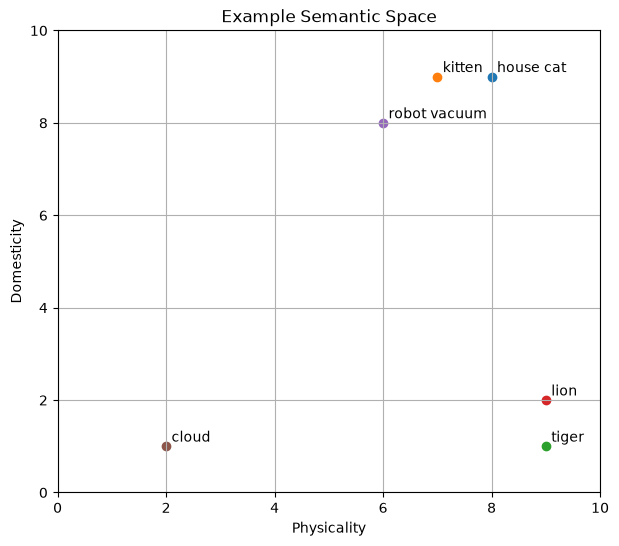

In [59]:
semantic_space = {
    "house cat": np.array([8, 9]),
    "kitten": np.array([7, 9]),
    "tiger": np.array([9, 1]),
    "lion": np.array([9, 2]),
    "robot vacuum": np.array([6, 8]),
    "cloud": np.array([2, 1])
}

plt.figure(figsize=(7, 6))

for word, vector in semantic_space.items():
    plt.scatter(vector[0], vector[1])
    plt.text(vector[0] + 0.1, vector[1] + 0.1, word)

plt.xlabel("Physicality")
plt.ylabel("Domesticity")
plt.title("Example Semantic Space")
plt.xlim(0, 10)
plt.ylim(0, 10)
plt.grid(True)
plt.show()

# Part 4: Euclidean Distance

Euclidean distance is the straight-line distance between two points.

Formula:

```text
distance = sqrt((x2 - x1)^2 + (y2 - y1)^2)
```

In vector search:

```text
smaller distance = closer meaning
```

In [60]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

cat = semantic_space["house cat"]
kitten = semantic_space["kitten"]
tiger = semantic_space["tiger"]

print("Distance between house cat and kitten:", euclidean_distance(cat, kitten))
print("Distance between house cat and tiger:", euclidean_distance(cat, tiger))

Distance between house cat and kitten: 1.0
Distance between house cat and tiger: 8.06225774829855


## Practice 2: Distance Comparisons

Calculate distances between:

1. tiger and lion
2. house cat and robot vacuum
3. cloud and tiger

Which pair is closest?

In [61]:
# Practice 2

pairs = [
    ("tiger", "lion"),
    ("house cat", "robot vacuum"),
    ("cloud", "tiger")
]

for a, b in pairs:
    distance = euclidean_distance(semantic_space[a], semantic_space[b])
    print(f"Distance between {a} and {b}: {distance:.2f}")

Distance between tiger and lion: 1.00
Distance between house cat and robot vacuum: 2.24
Distance between cloud and tiger: 7.00


# Part 5: Cosine Similarity

Cosine similarity measures the angle between two vectors.

It asks:

```text
Are these vectors pointing in a similar direction?
```

Cosine similarity is often used in semantic search.

Values:

```text
close to 1  → very similar
close to 0  → weakly related
close to -1 → opposite direction
```

In [62]:
def cosine_similarity(a, b):
    dot_product = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    return dot_product / (norm_a * norm_b)

doctor = embeddings_2d["doctor"]
physician = embeddings_2d["physician"]
banana = embeddings_2d["banana"]

print("Cosine similarity: doctor / physician:", cosine_similarity(doctor, physician))
print("Cosine similarity: doctor / banana:", cosine_similarity(doctor, banana))

Cosine similarity: doctor / physician: 0.9996981173951186
Cosine similarity: doctor / banana: 0.16243968706587425


## Practice 3: Cosine Similarity

Calculate cosine similarity between:

1. banana and apple
2. doctor and nurse
3. train and airplane

Which pair is most similar?

In [63]:
# Practice 3

pairs = [
    ("banana", "apple"),
    ("doctor", "nurse"),
    ("train", "airplane")
]

for a, b in pairs:
    similarity = cosine_similarity(embeddings_2d[a], embeddings_2d[b])
    print(f"Cosine similarity between {a} and {b}: {similarity:.4f}")

Cosine similarity between banana and apple: 0.9993
Cosine similarity between doctor and nurse: 0.9943
Cosine similarity between train and airplane: 0.9952


# Part 6: Euclidean Distance vs. Cosine Similarity

Both can measure vector similarity, but they focus on different things.

| Metric | Measures | Useful When |
|---|---|---|
| Euclidean Distance | Straight-line distance | You care about physical closeness |
| Cosine Similarity | Angle/direction | You care about semantic direction |

Many semantic search systems use cosine similarity because meaning is often captured well by vector direction.

In [64]:
A = np.array([1, 1])
B = np.array([2, 2])
C = np.array([1, 0])

print("Euclidean A-B:", euclidean_distance(A, B))
print("Cosine A-B:", cosine_similarity(A, B))

print("\nEuclidean A-C:", euclidean_distance(A, C))
print("Cosine A-C:", cosine_similarity(A, C))

Euclidean A-B: 1.4142135623730951
Cosine A-B: 0.9999999999999998

Euclidean A-C: 1.0
Cosine A-C: 0.7071067811865475


# Part 7: Keyword Search vs. Semantic Search

Keyword search looks for exact words.

Semantic search looks for meaning.

Example:

```text
Stored document: "Lightweight raincoat for wet weather"
Query: "waterproof outerwear"
```

Keyword search may fail because the exact words do not match.

Semantic search can succeed because the meanings are close.

In [65]:
documents = [
    "Lightweight raincoat for wet weather",
    "Insulated winter parka for snow",
    "Breathable windbreaker for spring hikes",
    "Trail running shoes with strong grip",
    "Stainless steel water bottle for camping"
]

query = "waterproof outerwear"

# Simple keyword search
keyword_results = []

for doc in documents:
    if query.lower() in doc.lower():
        keyword_results.append(doc)

print("Keyword search results:")
print(keyword_results)

Keyword search results:
[]


The keyword search returned nothing because the exact phrase does not appear.

Now we will simulate semantic search using simple hand-made vectors.

In [66]:
# Simple hand-made vectors for demonstration
# Dimensions: [waterproof, warmth, hiking, footwear, drinkware]

document_vectors = {
    "Lightweight raincoat for wet weather": np.array([0.95, 0.10, 0.50, 0.00, 0.00]),
    "Insulated winter parka for snow": np.array([0.60, 0.95, 0.30, 0.00, 0.00]),
    "Breathable windbreaker for spring hikes": np.array([0.50, 0.20, 0.80, 0.00, 0.00]),
    "Trail running shoes with strong grip": np.array([0.10, 0.00, 0.75, 0.95, 0.00]),
    "Stainless steel water bottle for camping": np.array([0.05, 0.00, 0.50, 0.00, 0.95])
}

query_vector = np.array([0.90, 0.10, 0.40, 0.00, 0.00])

scores = []

for doc, vector in document_vectors.items():
    score = cosine_similarity(query_vector, vector)
    scores.append((score, doc))

scores = sorted(scores, reverse=True)

print("Semantic search results:")
for score, doc in scores:
    print(f"{score:.4f} → {doc}")

Semantic search results:
0.9978 → Lightweight raincoat for wet weather
0.8275 → Breathable windbreaker for spring hikes
0.6558 → Insulated winter parka for snow
0.3244 → Trail running shoes with strong grip
0.2303 → Stainless steel water bottle for camping


## Practice 4: Concept Search

Change the query vector to represent:

```text
warm winter clothing
```

Hint: increase the warmth dimension.

Which document comes back first?

In [67]:
# Practice 4
# Dimensions: [waterproof, warmth, hiking, footwear, drinkware]

warm_winter_query = np.array([0.40, 0.95, 0.20, 0.00, 0.00])

scores = []

for doc, vector in document_vectors.items():
    score = cosine_similarity(warm_winter_query, vector)
    scores.append((score, doc))

scores = sorted(scores, reverse=True)

for score, doc in scores:
    print(f"{score:.4f} → {doc}")

0.9848 → Insulated winter parka for snow
0.5432 → Breathable windbreaker for spring hikes
0.5079 → Lightweight raincoat for wet weather
0.1490 → Trail running shoes with strong grip
0.1063 → Stainless steel water bottle for camping


# Part 8: Build a Simple Semantic Search Function

Let's wrap semantic search into a function.

In [68]:
def semantic_search(query_vector, document_vectors, n_results=3):
    scores = []

    for doc, vector in document_vectors.items():
        score = cosine_similarity(query_vector, vector)
        scores.append((score, doc))

    scores = sorted(scores, reverse=True)
    return scores[:n_results]

results = semantic_search(query_vector, document_vectors, n_results=3)

for score, doc in results:
    print(f"{score:.4f} → {doc}")

0.9978 → Lightweight raincoat for wet weather
0.8275 → Breathable windbreaker for spring hikes
0.6558 → Insulated winter parka for snow


# Part 9: What Is a Vector Database?

A vector database stores embeddings and retrieves the closest vectors.

It usually stores:

- documents
- embeddings
- unique IDs
- metadata
- sometimes URIs/file paths

It supports:

```text
Storage
Indexing
Similarity Search
Metadata Filtering
```

Vector databases are used in:

- semantic search
- AI memory
- RAG systems
- recommendation systems
- multimodal search

# Part 10: ChromaDB

ChromaDB is an open-source vector database.

It is useful for beginner AI projects because it can run locally.

Install it with:

```bash
pip install chromadb
```

If ChromaDB is not installed in your environment, the notebook will show a message instead of crashing.

In [69]:
try:
    import chromadb
    print("ChromaDB is installed.")
except ImportError:
    print("ChromaDB is not installed.")
    print("Install it with: pip install chromadb")

ChromaDB is installed.


# Part 11: Create a Persistent ChromaDB Client

A persistent client saves the database to a local folder.

```python
client = chromadb.PersistentClient(path="./chroma_db")
```

This creates a folder called:

```text
chroma_db
```

That folder stores the database.

In [70]:
try:
    import chromadb

    client = chromadb.PersistentClient(path="./chroma_db")
    collection = client.get_or_create_collection(name="student_memories")

    print("ChromaDB client and collection are ready.")

except ImportError:
    print("ChromaDB not available. Skip ChromaDB sections or install chromadb.")

ChromaDB client and collection are ready.


# Part 12: Add Documents to ChromaDB

To add data, ChromaDB needs:

1. Documents: the actual text
2. IDs: unique labels

Every ID must be unique.

In [71]:
try:
    collection.add(
        documents=[
            "My favorite movie genre is sci-fi",
            "I enjoy working out in the morning",
            "Pizza is my go-to comfort food"
        ],
        ids=["memory1", "memory2", "memory3"]
    )

    print("Documents added.")

except NameError:
    print("Collection is not available.")
except Exception as e:
    print("Something happened while adding documents:")
    print(e)
    print("This may happen if IDs already exist. Try changing the IDs.")

Documents added.


# Part 13: Query ChromaDB

Now we ask a question.

Even if the exact words do not match, ChromaDB can retrieve semantically related documents.

In [72]:
try:
    results = collection.query(
        query_texts=["What food do I like the most?"],
        n_results=2
    )

    print(results)

except NameError:
    print("Collection is not available.")
except Exception as e:
    print("Query failed:")
    print(e)

{'ids': [['memory3', 'memory2']], 'embeddings': None, 'documents': [['Pizza is my go-to comfort food', 'I enjoy working out in the morning']], 'uris': None, 'included': ['metadatas', 'documents', 'distances'], 'data': None, 'metadatas': [[None, None]], 'distances': [[1.0224535465240479, 1.4688174724578857]]}


## Practice 5: Store Three Fun Facts

Add three personal or fun facts to ChromaDB.

Rules:

1. Each document must be different.
2. Each ID must be unique.
3. Then query the collection using meaning, not exact words.

In [73]:
# Practice 5

try:
    collection.add(
        documents=[
            "I like studying at quiet coffee shops",
            "I prefer rainy weather for reading books",
            "My favorite weekend activity is hiking near mountains"
        ],
        ids=["fact1_unique", "fact2_unique", "fact3_unique"]
    )

    results = collection.query(
        query_texts=["Where do I enjoy learning?"],
        n_results=2
    )

    print(results)

except NameError:
    print("Collection is not available.")
except Exception as e:
    print("This may happen if the IDs already exist. Try changing the IDs.")
    print(e)

{'ids': [['fact1_unique', 'fact3_unique']], 'embeddings': None, 'documents': [['I like studying at quiet coffee shops', 'My favorite weekend activity is hiking near mountains']], 'uris': None, 'included': ['metadatas', 'documents', 'distances'], 'data': None, 'metadatas': [[None, None]], 'distances': [[0.8526162505149841, 1.3955352306365967]]}


# Part 14: Understanding n_results

The `n_results` parameter controls how many nearest neighbors are returned.

```python
n_results=1
```

returns only the closest result.

```python
n_results=3
```

returns the top 3 closest results.

More results can be useful, but they may become less relevant.

In [74]:
try:
    query = "What activity do I enjoy outdoors?"

    results_1 = collection.query(
        query_texts=[query],
        n_results=1
    )

    results_3 = collection.query(
        query_texts=[query],
        n_results=3
    )

    print("n_results=1")
    print(results_1)

    print("\nn_results=3")
    print(results_3)

except NameError:
    print("Collection is not available.")
except Exception as e:
    print(e)

n_results=1
{'ids': [['fact3_unique']], 'embeddings': None, 'documents': [['My favorite weekend activity is hiking near mountains']], 'uris': None, 'included': ['metadatas', 'documents', 'distances'], 'data': None, 'metadatas': [[None]], 'distances': [[0.6539279818534851]]}

n_results=3
{'ids': [['fact3_unique', 'memory2', 'memory1']], 'embeddings': None, 'documents': [['My favorite weekend activity is hiking near mountains', 'I enjoy working out in the morning', 'My favorite movie genre is sci-fi']], 'uris': None, 'included': ['metadatas', 'documents', 'distances'], 'data': None, 'metadatas': [[None, None, None]], 'distances': [[0.6539279818534851, 1.27702796459198, 1.3410981893539429]]}


# Part 15: Add Metadata and URIs

Metadata is extra information stored with each document.

Examples:

- category
- product type
- file path
- image URI
- source

A URI tells the system where the original file or image is located.

In [75]:
try:
    product_collection = client.get_or_create_collection(name="product_search_demo")

    product_collection.add(
        documents=[
            "Vintage leather jacket with silver zippers",
            "Lightweight raincoat for wet weather",
            "Trail running shoes with strong grip",
            "Insulated winter parka for snow",
            "Breathable windbreaker for spring hikes"
        ],
        ids=["product1", "product2", "product3", "product4", "product5"],
        metadatas=[
            {"category": "clothing", "uri": "./images/leather_jacket.jpg"},
            {"category": "clothing", "uri": "./images/raincoat.jpg"},
            {"category": "footwear", "uri": "./images/trail_shoes.jpg"},
            {"category": "clothing", "uri": "./images/winter_parka.jpg"},
            {"category": "clothing", "uri": "./images/windbreaker.jpg"}
        ]
    )

    print("Products added.")

except NameError:
    print("ChromaDB client is not available.")
except Exception as e:
    print("This may happen if IDs already exist. Try changing IDs or collection name.")
    print(e)

Products added.


In [76]:
try:
    results = product_collection.query(
        query_texts=["waterproof outerwear"],
        n_results=3
    )

    print(results)

except NameError:
    print("Product collection is not available.")
except Exception as e:
    print(e)

{'ids': [['product2', 'product1', 'product5']], 'embeddings': None, 'documents': [['Lightweight raincoat for wet weather', 'Vintage leather jacket with silver zippers', 'Breathable windbreaker for spring hikes']], 'uris': None, 'included': ['metadatas', 'documents', 'distances'], 'data': None, 'metadatas': [[{'uri': './images/raincoat.jpg', 'category': 'clothing'}, {'category': 'clothing', 'uri': './images/leather_jacket.jpg'}, {'category': 'clothing', 'uri': './images/windbreaker.jpg'}]], 'distances': [[1.0793969631195068, 1.1827411651611328, 1.243520975112915]]}


# Part 16: Metadata Map

For multimodal systems, a vector database may store an image embedding and a URI pointing to the actual image file.

Example:

```text
Document ID: product2
Text: Lightweight raincoat for wet weather
URI: ./images/raincoat.jpg
```

The vector database stores the searchable meaning.  
The URI tells the app where to find the original image.

In [77]:
metadata_map = [
    {"id": "product1", "uri": "./images/leather_jacket.jpg"},
    {"id": "product2", "uri": "./images/raincoat.jpg"},
    {"id": "product3", "uri": "./images/trail_shoes.jpg"},
    {"id": "product4", "uri": "./images/winter_parka.jpg"},
    {"id": "product5", "uri": "./images/windbreaker.jpg"}
]

for item in metadata_map:
    print(item["id"], "→", item["uri"])

product1 → ./images/leather_jacket.jpg
product2 → ./images/raincoat.jpg
product3 → ./images/trail_shoes.jpg
product4 → ./images/winter_parka.jpg
product5 → ./images/windbreaker.jpg


# Part 17: Word Neighbors Activity

Goal: Determine how computers group items by meaning rather than exact words.

Choose a theme:

- Outdoor Adventure Gear
- Pet Supplies
- Food Delivery
- Fitness Equipment
- Study Tools

Then write one anchor description and five possible neighbors.

In [78]:
# Word Neighbors Activity

theme = "Outdoor Adventure Gear"

anchor = "A lightweight jacket for breezy spring weather"

neighbors = [
    "Breathable windbreaker for mild hiking days",
    "Thin rain shell for wet spring walks",
    "Insulated winter parka for freezing snow",
    "Cotton t-shirt for summer workouts",
    "Camping lantern with rechargeable battery"
]

print("Theme:", theme)
print("Anchor:", anchor)
print("\nRank these by semantic closeness:")

for i, item in enumerate(neighbors, start=1):
    print(i, item)

Theme: Outdoor Adventure Gear
Anchor: A lightweight jacket for breezy spring weather

Rank these by semantic closeness:
1 Breathable windbreaker for mild hiking days
2 Thin rain shell for wet spring walks
3 Insulated winter parka for freezing snow
4 Cotton t-shirt for summer workouts
5 Camping lantern with rechargeable battery


## Practice 6: Rank the Neighbors

Manually rank the items above from most similar to least similar.

Then explain why the most similar item is close in meaning even if it uses different words.

In [79]:
# Practice 6: Write your ranking as comments

# 1.
# 2.
# 3.
# 4.
# 5.

# Explanation:

# Part 18: Keyword Trap

A keyword trap happens when text uses the same words but means something different.

Example anchor:

```text
A lightweight jacket for breezy spring weather
```

Keyword trap:

```text
A light for a jacket pocket
```

This uses similar words like `light` and `jacket`, but the meaning is different.

Semantic search is better because it compares meaning, not just exact words.

In [80]:
anchor = "A lightweight jacket for breezy spring weather"
keyword_trap = "A light for a jacket pocket"

print("Anchor:", anchor)
print("Keyword trap:", keyword_trap)
print("\nQuestion: Why might keyword search be fooled?")
print("Answer: It sees similar words but may miss the different meaning.")

Anchor: A lightweight jacket for breezy spring weather
Keyword trap: A light for a jacket pocket

Question: Why might keyword search be fooled?
Answer: It sees similar words but may miss the different meaning.


# Part 19: CLIP Preview

CLIP stands for Contrastive Language-Image Pre-training.

It is a model that connects text and images in a shared vector space.

Example:

```text
Text: "a red running shoe"
Image: photo of a red running shoe
```

CLIP places both close together in vector space.

This makes multimodal search possible:

```text
Search with text → retrieve images
Search with image → retrieve related text
```

# Final Reflection

Answer these questions:

1. Why are token IDs not enough to represent meaning?
2. What is an embedding?
3. Why is vector space useful?
4. What does semantic similarity mean?
5. What is Euclidean distance?
6. What is cosine similarity?
7. Why is semantic search better than keyword search in some cases?
8. What does a vector database store?
9. What does ChromaDB’s `.add()` function need?
10. What does ChromaDB’s `.query()` function do?
11. What does `n_results` control?
12. Why are metadata and URIs useful?
13. How does this lesson connect to CLIP and multimodal AI?

In [81]:
# Final Reflection Answers

# 1.
# 2.
# 3.
# 4.
# 5.
# 6.
# 7.
# 8.
# 9.
# 10.
# 11.
# 12.
# 13.